# Predição de AVC — APS2: Avaliação, interpretação e discussão

**Aluno:** Matheus Henrique Pereira Borba · **Entrega (APS2):** 27/10/2026

**Dataset:** [Stroke Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) (Kaggle, fedesoriano)

Seções 2 a 4 da APS2. Usa os modelos ajustados e salvos pelo notebook 03; aqui o conjunto de teste é usado pela primeira vez, e uma única vez, sem nenhuma decisão de modelagem tomada a partir dele.

## Setup

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.inspection import permutation_importance
from sklearn.metrics import (RocCurveDisplay, PrecisionRecallDisplay, accuracy_score, average_precision_score,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110})

AZUL, LARANJA, VIOLETA, CINZA = "#2a78d6", "#eb6834", "#4a3aa7", "#898781"
TARGET = "stroke"

# Nomes legíveis das features transformadas, usados nos gráficos de interpretação
ROTULOS = {
    "age": "idade", "avg_glucose_level": "glicose média", "bmi": "IMC", "missingindicator_bmi": "IMC ausente",
    "hypertension": "hipertensão", "heart_disease": "doença cardíaca", "gender_Male": "gênero masculino",
    "ever_married_Yes": "já foi casado(a)", "Residence_type_Urban": "área urbana",
    "work_type_Govt_job": "trabalho: público", "work_type_Never_worked": "trabalho: nunca trabalhou",
    "work_type_Private": "trabalho: privado", "work_type_Self-employed": "trabalho: autônomo", "work_type_children": "trabalho: criança",
    "smoking_status_Unknown": "tabagismo: desconhecido", "smoking_status_formerly smoked": "tabagismo: ex-fumante",
    "smoking_status_never smoked": "tabagismo: nunca fumou", "smoking_status_smokes": "tabagismo: fuma",
}

C:\dev\Projetos\Insper\APS-ML\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Carregamento

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"

train, test = pd.read_csv(PROCESSED / "train.csv"), pd.read_csv(PROCESSED / "test.csv")
X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_test, y_test = test.drop(columns=TARGET), test[TARGET]

modelos = joblib.load(ROOT / "models" / "modelos.joblib")
modelo_final = modelos["modelo_final"]
pipeline_rf = modelo_final.estimator_
LIMIAR = modelo_final.threshold

print(f"teste {X_test.shape}, {y_test.sum()} casos de AVC ({y_test.mean():.1%})")
print(f"Modelo final: {pipeline_rf['modelo']}, {pipeline_rf['prep'].get_feature_names_out().size} features, limiar {LIMIAR:.3f}")

teste (1022, 10), 50 casos de AVC (4.9%)
Modelo final: RandomForestClassifier(max_depth=5, min_samples_leaf=5, n_estimators=300,
                       random_state=42), 11 features, limiar 0.090


# Seção 2 — Avaliação do melhor modelo no conjunto de teste

### 2.1 Métricas

As métricas pedidas (accuracy, precision, recall e F1 da classe AVC), mais ROC-AUC e PR-AUC, que não dependem do limiar. Duas linhas de referência: o Dummy e a mesma floresta com o limiar padrão de 0,5.

In [3]:
proba = modelo_final.predict_proba(X_test)[:, 1]
previsto = modelo_final.predict(X_test).astype(bool)


def metricas(y_previsto, y_proba):
    return pd.Series({"Accuracy": accuracy_score(y_test, y_previsto), "Precision": precision_score(y_test, y_previsto, zero_division=0),
                      "Recall": recall_score(y_test, y_previsto), "F1-score": f1_score(y_test, y_previsto),
                      "ROC-AUC": roc_auc_score(y_test, y_proba), "PR-AUC": average_precision_score(y_test, y_proba)})


proba_dummy = modelos["dummy"].predict_proba(X_test)[:, 1]
pd.DataFrame({
    "Dummy (sempre 'sem AVC')": metricas(modelos["dummy"].predict(X_test), proba_dummy),
    "Random Forest, limiar padrão 0,5": metricas(proba >= 0.5, proba),
    f"Random Forest, limiar {LIMIAR:.3f} (modelo final)": metricas(previsto, proba),
}).T.round(3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Dummy (sempre 'sem AVC'),0.951,0.000,0.00,0.000,0.500,0.049
"Random Forest, limiar padrão 0,5",0.951,0.000,0.00,0.000,0.835,0.214
"Random Forest, limiar 0.090 (modelo final)",0.830,0.174,0.66,0.275,0.835,0.214


- **A acurácia engana:** o Dummy e a floresta com limiar 0,5 têm 95,1% e não encontram nenhum AVC. O modelo final tem acurácia menor (83,0%) justamente porque sinaliza pacientes.
- **Recall 0,66:** o modelo encontra 33 dos 50 AVCs do teste.
- **Precisão 0,17:** cerca de 1 em cada 6 alertas é AVC. É baixa em termos absolutos, mas é 3,6 vezes a prevalência: o grupo sinalizado tem risco 3,6 vezes maior que o paciente médio.
- **F1 0,275:** puxado pela precisão baixa; o limiar foi escolhido pelo F2, que favorece o recall.
- **ROC-AUC 0,835 e PR-AUC 0,214**, contra 0,853 e 0,269 na validação cruzada. A queda da PR-AUC está dentro da variação entre dobras (desvio de 0,03 a 0,06) e é esperada com só 50 casos no teste. Recall e precisão ficaram perto do previsto na validação (0,67 e 0,18), então o limiar escolhido no treino se transferiu bem.

### 2.2 Matriz de confusão

A matriz cruza a classe real com a prevista. Cores e percentuais são por linha: a linha de baixo mostra o recall (66%) e a de cima a especificidade (84%).

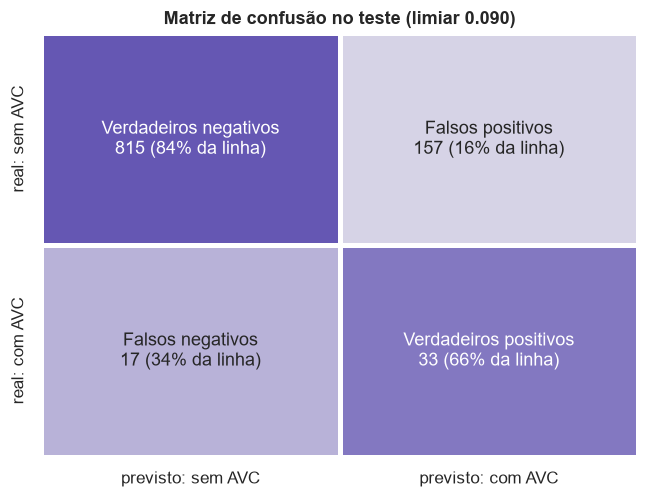

De 50 pacientes com AVC, o modelo sinaliza 33 e deixa passar 17.
De 190 alertas, 33 são AVC: 1 caso a cada 5.8 alertas.


In [4]:
matriz = confusion_matrix(y_test, previsto)
rotulos_celula = np.array([["Verdadeiros negativos", "Falsos positivos"], ["Falsos negativos", "Verdadeiros positivos"]])
anotacoes = [[f"{rotulos_celula[i, j]}\n{matriz[i, j]} ({matriz[i, j] / matriz[i].sum():.0%} da linha)" for j in range(2)] for i in range(2)]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(matriz / matriz.sum(axis=1, keepdims=True), annot=anotacoes, fmt="", cmap=sns.light_palette(VIOLETA, as_cmap=True),
            vmin=0, vmax=1, cbar=False, linewidths=2, linecolor="white", ax=ax,
            xticklabels=["previsto: sem AVC", "previsto: com AVC"], yticklabels=["real: sem AVC", "real: com AVC"])
ax.set(title=f"Matriz de confusão no teste (limiar {LIMIAR:.3f})")
plt.show()

vn, fp, fn, vp = matriz.ravel()
print(f"De {vp + fn} pacientes com AVC, o modelo sinaliza {vp} e deixa passar {fn}.")
print(f"De {vp + fp} alertas, {vp} são AVC: 1 caso a cada {(vp + fp) / vp:.1f} alertas.")

In [5]:
grupo = np.select([(y_test == 1) & previsto, (y_test == 1) & ~previsto, (y_test == 0) & previsto],
                  ["verdadeiro positivo", "falso negativo", "falso positivo"], "verdadeiro negativo")
X_test.assign(grupo=grupo).groupby("grupo").agg(
    pacientes=("age", "size"), idade_mediana=("age", "median"), glicose_mediana=("avg_glucose_level", "median"),
    hipertensão_pct=("hypertension", lambda s: s.mean() * 100), doença_cardíaca_pct=("heart_disease", lambda s: s.mean() * 100),
).loc[["verdadeiro positivo", "falso negativo", "falso positivo", "verdadeiro negativo"]].round(1)

,pacientes,idade_mediana,glicose_mediana,hipertensão_pct,doença_cardíaca_pct
grupo,,,,,
verdadeiro positivo,33,78.0,133.2,33.3,33.3
falso negativo,17,57.0,92.6,5.9,0.0
falso positivo,157,74.0,151.2,40.1,14.0
verdadeiro negativo,815,38.0,89.2,4.4,1.3


**Falsos negativos (17):** pacientes com AVC que o modelo não sinaliza. São mais jovens (mediana de 57 anos, contra 78 dos verdadeiros positivos) e quase sem fatores de risco registrados: 6% com hipertensão, nenhum com doença cardíaca e glicose mediana normal (93). O modelo não erra ao acaso: erra nos AVCs atípicos, que as features disponíveis não distinguem de pacientes saudáveis.

**Falsos positivos (157):** pacientes sem AVC sinalizados. Têm o perfil de risco dos verdadeiros positivos (mediana de 74 anos, 40% hipertensos, glicose mediana de 151): pelo que o dataset registra, são pacientes de alto risco que não tiveram AVC, ou ainda não tiveram. Em triagem, é um erro aceitável, porque são os pacientes que mais se beneficiariam de acompanhamento.

O custo prático: para encontrar 33 dos 50 casos, o modelo sinaliza 190 pacientes (19% do teste), quase 6 alertas por caso verdadeiro.

### 2.3 Curva ROC

A curva ROC mostra a taxa de verdadeiros positivos (recall) contra a de falsos positivos em todos os limiares. A ROC-AUC é a probabilidade de um paciente com AVC sorteado receber probabilidade maior que um paciente sem AVC sorteado. Ao lado está a curva precisão-recall, que corresponde à métrica de seleção. O ponto laranja é o limiar escolhido.

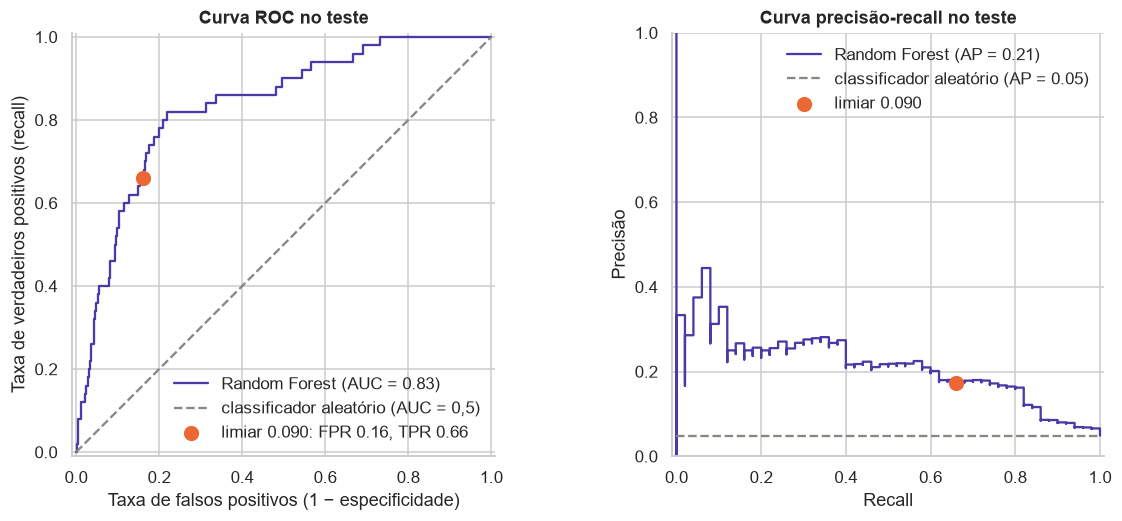

ROC-AUC: teste 0.835
PR-AUC: teste 0.214


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, proba, name="Random Forest", curve_kwargs={"color": VIOLETA}, ax=axes[0], plot_chance_level=True,
                                 chance_level_kw={"color": CINZA, "ls": "--", "label": "classificador aleatório (AUC = 0,5)"})
fpr_ponto, tpr_ponto = fp / (fp + vn), vp / (vp + fn)
axes[0].scatter(fpr_ponto, tpr_ponto, color=LARANJA, s=80, zorder=3, label=f"limiar {LIMIAR:.3f}: FPR {fpr_ponto:.2f}, TPR {tpr_ponto:.2f}")
axes[0].set(title="Curva ROC no teste", xlabel="Taxa de falsos positivos (1 − especificidade)", ylabel="Taxa de verdadeiros positivos (recall)")
axes[0].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(y_test, proba, name="Random Forest", curve_kwargs={"color": VIOLETA}, ax=axes[1], plot_chance_level=True,
                                        chance_level_kw={"color": CINZA, "ls": "--", "label": f"classificador aleatório (AP = {y_test.mean():.2f})"})
axes[1].scatter(tpr_ponto, vp / (vp + fp), color=LARANJA, s=80, zorder=3, label=f"limiar {LIMIAR:.3f}")
axes[1].set(title="Curva precisão-recall no teste", xlabel="Recall", ylabel="Precisão", ylim=(0, 1))
axes[1].legend(loc="upper right")
plt.show()

print(f"ROC-AUC: teste {roc_auc_score(y_test, proba):.3f}")
print(f"PR-AUC: teste {average_precision_score(y_test, proba):.3f}")

**ROC-AUC = 0,835:** em 83,5% dos pares (paciente com AVC, paciente sem AVC), o paciente com AVC recebe probabilidade maior. A curva sobe rápido no início: com 20% de falsos positivos já chega a ~80% de recall. O ponto de operação (16% de falsos positivos, 66% de recall) fica nesse trecho de melhor custo-benefício.

**A curva precisão-recall mostra o outro lado:** a precisão fica entre 0,2 e 0,3 até 40% de recall e cai depois. A diferença entre as duas curvas é o efeito do desbalanceamento: 16% de falsos positivos parece pouco, mas são 157 pacientes, quase 5 vezes os 33 verdadeiros positivos. É por isso que a PR-AUC foi a métrica de seleção.

# Seção 3 — Interpretação e explicabilidade

### 3.1 Regressão logística: coeficientes de maior magnitude

O modelo linear é a regressão logística ajustada no notebook 03 (L1, C = 0,32), com o pipeline da APS1. As contínuas estão padronizadas, então seus coeficientes medem o efeito de +1 desvio padrão; as binárias medem ter contra não ter. Cada coeficiente é a mudança no log da chance de AVC com as demais features fixas, e exp(coef) é a razão de chances.

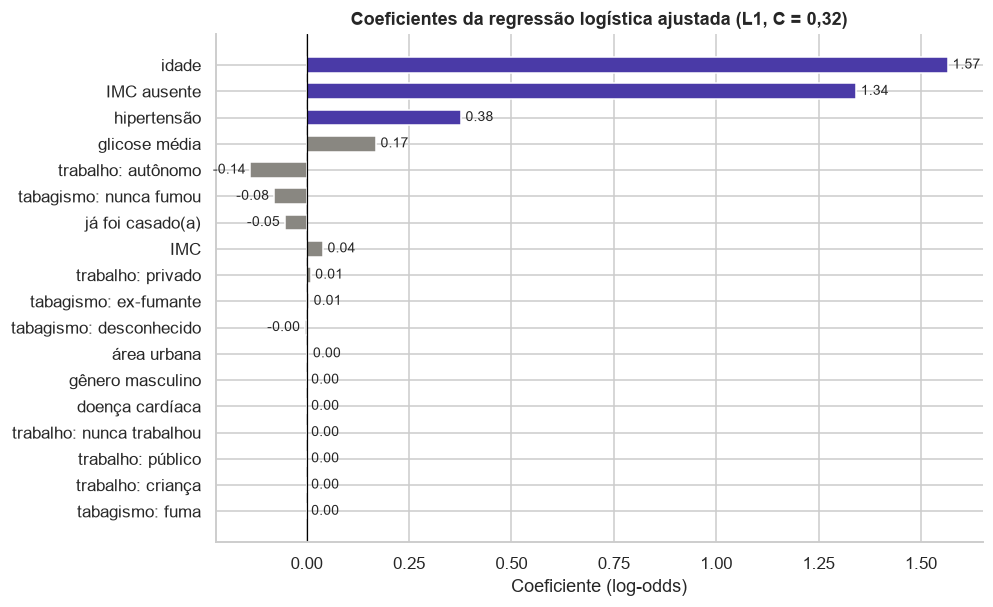

Coeficientes zerados pela penalidade L1: 6 de 18: doença cardíaca, gênero masculino, trabalho: público, trabalho: nunca trabalhou, trabalho: criança, tabagismo: fuma


,coeficiente,razão de chances exp(coef),unidade
idade,1.57,4.79,"+1 desvio padrão (22,6 anos)"
IMC ausente,1.34,3.83,ter vs. não ter
hipertensão,0.38,1.46,ter vs. não ter


In [7]:
logistica = modelos["logistica"]
coeficientes = pd.Series(logistica["modelo"].coef_[0], index=logistica["prep"].get_feature_names_out()).rename(ROTULOS)
ordem = coeficientes.abs().sort_values(ascending=False).index
top3_lr = ordem[:3]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ordem, coeficientes[ordem], color=[VIOLETA if f in top3_lr else CINZA for f in ordem], height=0.6)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, fontsize=9)
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set(title="Coeficientes da regressão logística ajustada (L1, C = 0,32)", xlabel="Coeficiente (log-odds)")
plt.show()

print(f"Coeficientes zerados pela penalidade L1: {(coeficientes == 0).sum()} de {len(coeficientes)}:", ", ".join(coeficientes[coeficientes == 0].index))
pd.DataFrame({"coeficiente": coeficientes[top3_lr], "razão de chances exp(coef)": np.exp(coeficientes[top3_lr]),
              "unidade": ["+1 desvio padrão (22,6 anos)" if f == "idade" else "ter vs. não ter" for f in top3_lr]}).round(2)

1. **Idade (coeficiente 1,57, razão de chances 4,8):** cada 22,6 anos a mais multiplicam a chance de AVC por 4,8. É de longe o maior efeito, como a APS1 antecipava (mediana de 70 anos nos casos contra 43).
2. **IMC ausente (1,34; 3,8):** sem IMC registrado, a chance é 3,8 vezes maior. Não é um efeito biológico: é o sinal encontrado na tarefa 1.5 da APS1 (19,9% de AVC entre quem não tem IMC), que o indicador de ausência criado no pré-processamento preservou. A seção 4.2 discute o que isso diz sobre a coleta.
3. **Hipertensão (0,38; 1,5):** hipertensos têm chance 46% maior, já descontada a idade, como na APS1, em que a hipertensão elevava a taxa em todas as faixas etárias.

A penalidade L1 zerou 6 coeficientes, entre eles gênero e três colunas de trabalho: a mesma direção da mudança de pipeline da seção 1.5, obtida de forma independente. Também zerou a doença cardíaca, que a APS1 apontava como fator de risco. Com L1, entre features que se sobrepõem, o modelo tende a manter uma e zerar as outras, e parte do efeito da doença cardíaca já está na idade e na hipertensão; o zero não quer dizer que ela não importa.

Uma ressalva na comparação: +1 desvio padrão de idade e ter hipertensão são unidades diferentes, então a ordem entre contínuas e binárias depende da escala escolhida no pré-processamento.

### 3.2 Random Forest: features de maior importância

O ensemble é a Random Forest final. A importância por impureza (`feature_importances_`) mede quanto cada feature reduz o índice de Gini nas divisões, em média sobre as árvores. Ela é calculada no treino e tende a favorecer variáveis contínuas, que oferecem mais pontos de corte (Strobl et al., 2007). Por isso o gráfico da direita confere o resultado com a importância por permutação no teste: quanto a PR-AUC cai quando os valores de uma variável original são embaralhados.

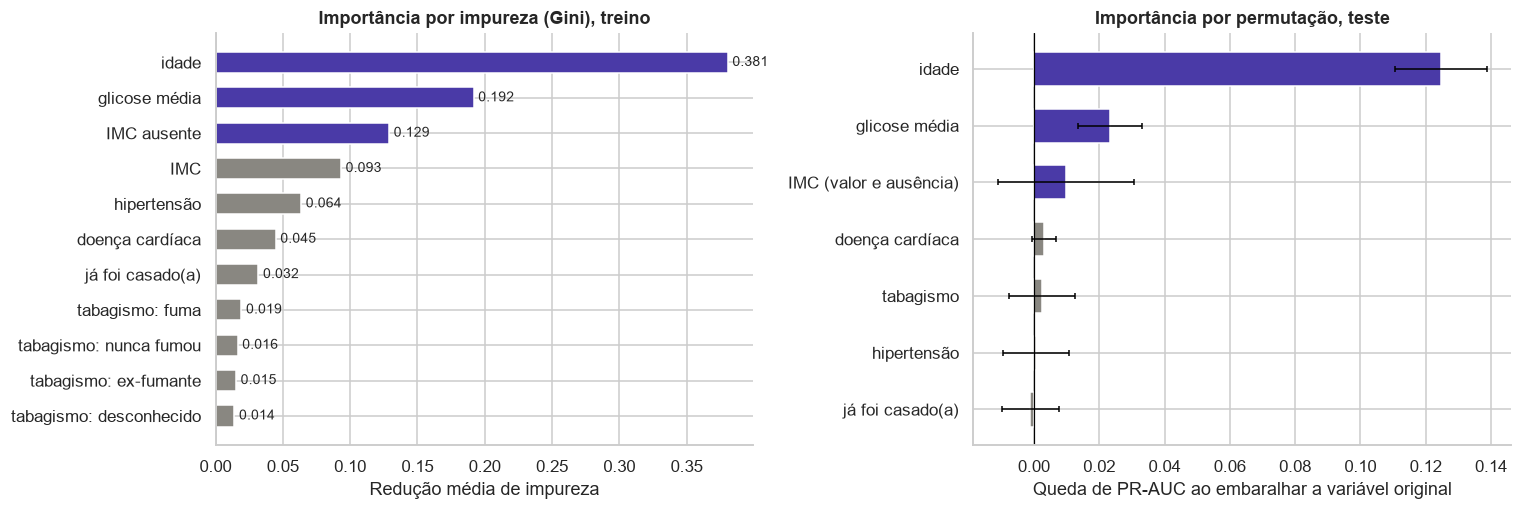

,importância (impureza)
idade,0.381
glicose média,0.192
IMC ausente,0.129


In [8]:
prep, floresta = pipeline_rf["prep"], pipeline_rf["modelo"]
nomes_rf = pd.Index(prep.get_feature_names_out()).map(lambda f: ROTULOS.get(f, f))
importancia = pd.Series(floresta.feature_importances_, index=nomes_rf).sort_values(ascending=False)

# Permuta as variáveis originais usadas pelo modelo; embaralhar o bmi embaralha também a sua ausência
ORIGINAIS = {"age": "idade", "avg_glucose_level": "glicose média", "bmi": "IMC (valor e ausência)", "hypertension": "hipertensão",
             "heart_disease": "doença cardíaca", "ever_married": "já foi casado(a)", "smoking_status": "tabagismo"}
permutacao = permutation_importance(pipeline_rf, X_test, y_test, scoring="average_precision", n_repeats=30,
                                    random_state=RANDOM_STATE, n_jobs=-1)
importancia_perm = (pd.DataFrame({"queda média de PR-AUC": permutacao.importances_mean, "desvio": permutacao.importances_std},
                                 index=X_test.columns).loc[list(ORIGINAIS)].rename(ORIGINAIS)
                    .sort_values("queda média de PR-AUC", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].barh(importancia.index, importancia, color=[VIOLETA] * 3 + [CINZA] * (len(importancia) - 3), height=0.6)
axes[0].bar_label(axes[0].containers[0], fmt="%.3f", padding=3, fontsize=9)
axes[0].set(title="Importância por impureza (Gini), treino", xlabel="Redução média de impureza")
axes[1].barh(importancia_perm.index, importancia_perm["queda média de PR-AUC"], xerr=importancia_perm["desvio"],
             color=[VIOLETA] * 3 + [CINZA] * (len(importancia_perm) - 3), height=0.6, error_kw={"ecolor": "black", "capsize": 2, "lw": 1})
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(title="Importância por permutação, teste", xlabel="Queda de PR-AUC ao embaralhar a variável original")
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

importancia.head(3).to_frame("importância (impureza)").round(3)

As 3 features mais importantes por impureza:

1. **Idade (0,381):** quase 40% de toda a redução de impureza.
2. **Glicose média (0,192):** o grupo com glicose alta, mantido como outlier na APS1, é o segundo sinal mais forte.
3. **IMC ausente (0,129):** de novo o indicador de ausência, como na regressão logística.

A permutação confirma a ordem das duas primeiras: embaralhar a idade derruba a PR-AUC em 0,12, mais da metade do valor do modelo, e a glicose em 0,02. As demais ficam perto de zero e com desvio maior que a média: individualmente, hipertensão e doença cardíaca acrescentam pouco a um modelo que já sabe a idade e a glicose. A diferença entre os métodos ilustra o viés citado: o IMC contínuo aparece em 4º por impureza (0,093) porque oferece muitos cortes possíveis, mas embaralhá-lo, junto com a sua ausência, tem efeito pequeno e instável.

### 3.3 SHAP: importância global e explicação de predições individuais

SHAP divide a diferença entre a predição de um paciente e a predição média entre as features, usando os valores de Shapley da teoria dos jogos (Lundberg & Lee, 2017). Para florestas, o TreeExplainer calcula esses valores de forma exata e rápida (Lundberg et al., 2020). Aqui estão na escala de probabilidade: o valor base é 0,049 (a probabilidade média) e, para cada paciente, valor base + soma dos SHAP = probabilidade prevista, o que a célula abaixo verifica.

In [9]:
X_test_prep = prep.transform(X_test)
explicacao = shap.TreeExplainer(floresta)(X_test_prep)[:, :, 1]
explicacao.feature_names = list(nomes_rf)

# Os valores exibidos ficam na escala original (anos, mg/dL, kg/m²); a floresta é invariante a log e padronização
explicacao.data = X_test_prep.assign(age=X_test["age"].to_numpy(), avg_glucose_level=X_test["avg_glucose_level"].to_numpy(),
                                     bmi=X_test["bmi"].to_numpy()).to_numpy()

soma = explicacao.base_values + explicacao.values.sum(axis=1)
print(f"Valor base (probabilidade média no treino): {explicacao.base_values[0]:.3f}")
print(f"Maior diferença entre valor base + soma dos SHAP e a probabilidade prevista: {np.abs(soma - proba).max():.1e}")

Valor base (probabilidade média no treino): 0.049
Maior diferença entre valor base + soma dos SHAP e a probabilidade prevista: 6.1e-16


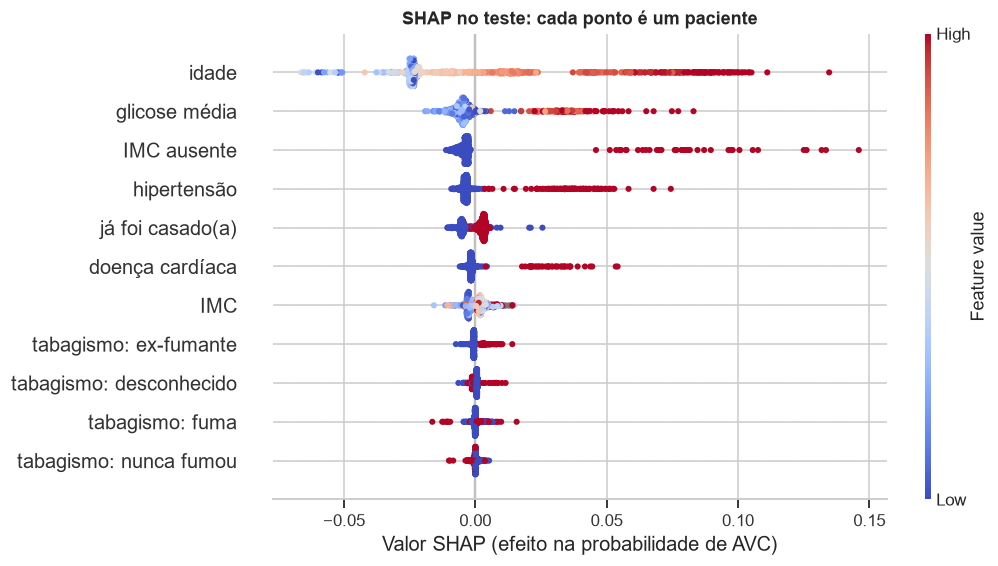

In [10]:
shap.plots.beeswarm(explicacao, max_display=11, color=plt.get_cmap("coolwarm"), show=False, plot_size=(9, 5.5))
plt.title("SHAP no teste: cada ponto é um paciente", fontweight="bold")
plt.xlabel("Valor SHAP (efeito na probabilidade de AVC)")
plt.show()

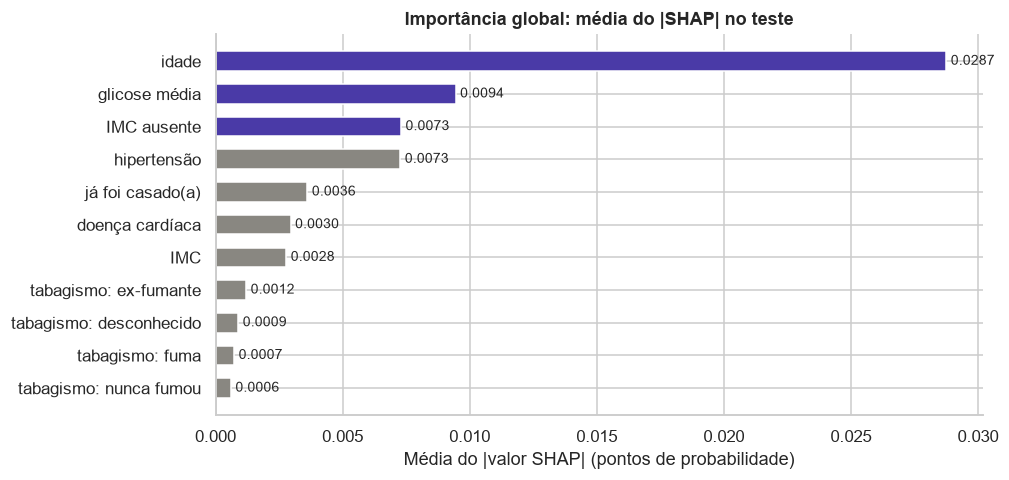

In [11]:
shap_medio = pd.Series(np.abs(explicacao.values).mean(axis=0), index=nomes_rf).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(shap_medio.index, shap_medio, color=[VIOLETA] * 3 + [CINZA] * (len(shap_medio) - 3), height=0.6)
ax.bar_label(ax.containers[0], fmt="%.4f", padding=3, fontsize=9)
ax.invert_yaxis()
ax.set(title="Importância global: média do |SHAP| no teste", xlabel="Média do |valor SHAP| (pontos de probabilidade)")
plt.show()

**Importância global.** Na média do |SHAP| a ordem é idade, glicose, IMC ausente e hipertensão: as três primeiras são as mesmas da importância por impureza. O beeswarm mostra também a direção e a forma de cada efeito:

- **idade:** idades baixas (azul) tiram até ~0,07 da probabilidade e idades altas (vermelho) somam até ~0,13. O efeito cresce acelerado entre os mais velhos, a não linearidade que a APS1 descrevia (quase nenhum AVC antes dos 40);
- **glicose:** só os valores altos empurram a predição para cima; os normais quase não mexem. É o efeito de limiar visto na APS1, que a regressão logística, linear na glicose, não captura;
- **IMC ausente:** quando presente, soma entre +0,05 e +0,15, o maior efeito individual do modelo;
- **hipertensão e doença cardíaca:** ter a condição soma até ~0,07; não ter quase não muda nada;
- **IMC e tabagismo:** efeitos pequenos e misturados, coerentes com a APS1.

**Predições individuais.** Três pacientes do teste, escolhidos para cobrir acerto e os dois tipos de erro: o verdadeiro positivo com maior probabilidade, o falso negativo com menor probabilidade (o caso que o modelo mais errou) e o falso positivo com maior probabilidade.

In [12]:
casos = {
    "verdadeiro positivo": np.flatnonzero((y_test == 1) & previsto)[proba[(y_test == 1) & previsto].argmax()],
    "falso negativo": np.flatnonzero((y_test == 1) & ~previsto)[proba[(y_test == 1) & ~previsto].argmin()],
    "falso positivo": np.flatnonzero((y_test == 0) & previsto)[proba[(y_test == 0) & previsto].argmax()],
}
X_test.iloc[list(casos.values())].assign(caso=list(casos), AVC_real=y_test.iloc[list(casos.values())].to_numpy(),
                                         probabilidade=proba[list(casos.values())].round(3)).set_index("caso")

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,AVC_real,probabilidade
caso,,,,,,,,,,,,
verdadeiro positivo,Male,78.0,0,1,Yes,Private,Urban,219.84,NaN,Unknown,1,0.305
falso negativo,Female,14.0,0,0,No,children,Rural,57.93,30.9,Unknown,1,0.010
falso positivo,Male,78.0,1,0,Yes,Self-employed,Urban,90.19,NaN,Unknown,0,0.336


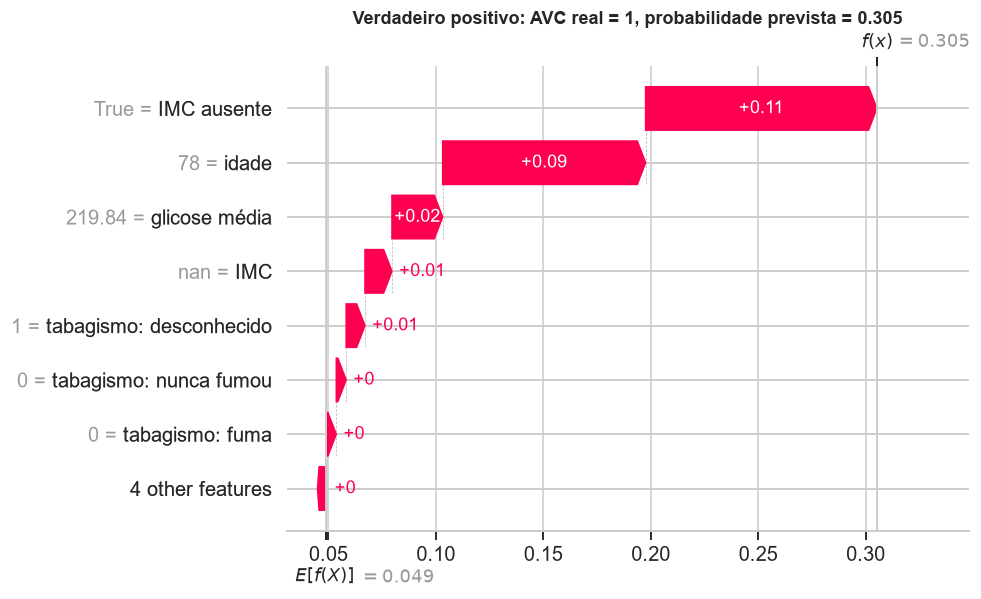

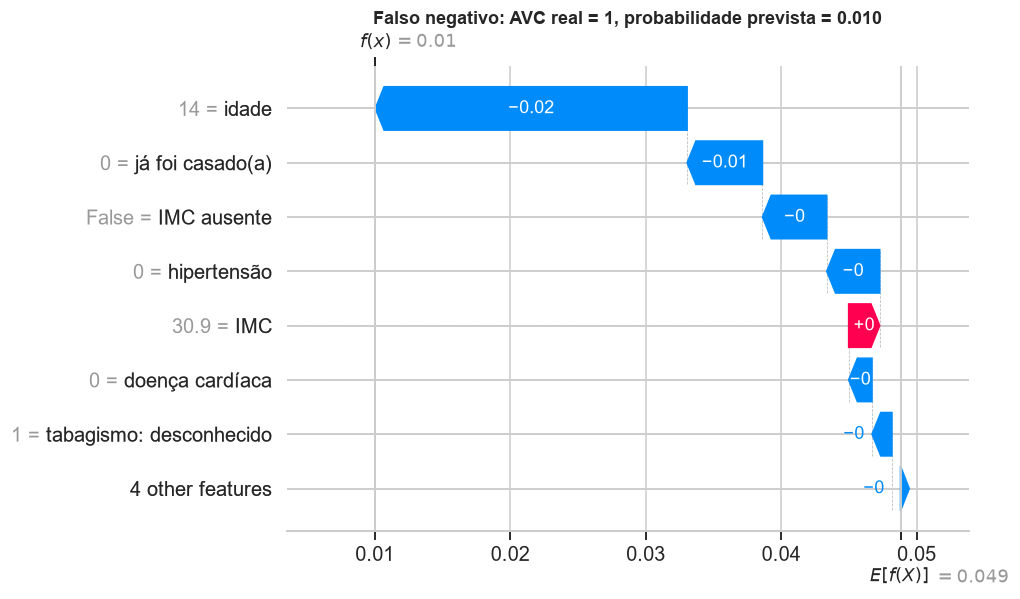

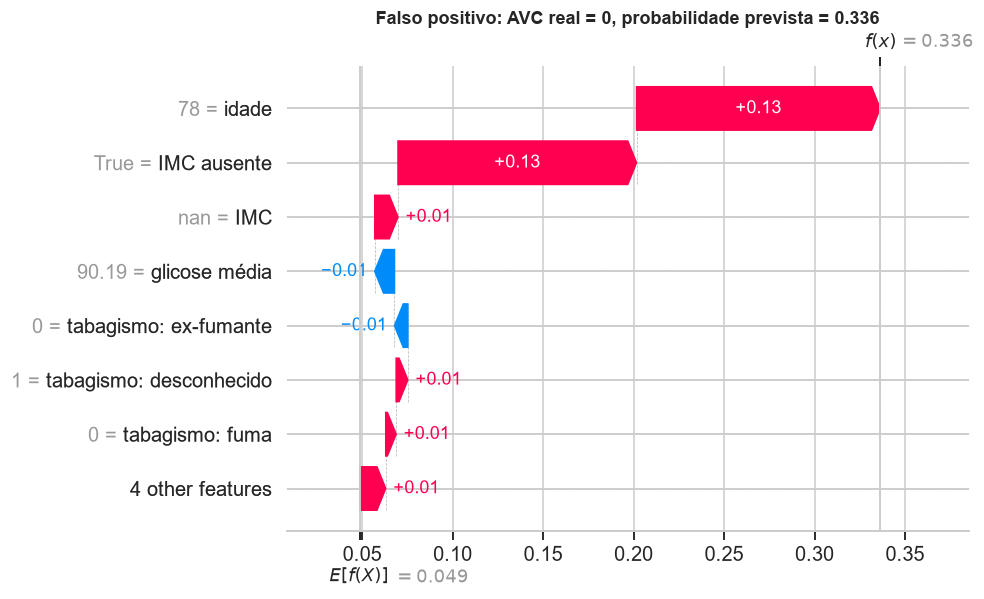

In [13]:
for nome, i in casos.items():
    shap.plots.waterfall(explicacao[i], max_display=8, show=False)
    plt.title(f"{nome.capitalize()}: AVC real = {y_test.iloc[i]}, probabilidade prevista = {proba[i]:.3f}", fontweight="bold")
    plt.show()

Cada gráfico parte do valor base (0,049, embaixo) e soma a contribuição de cada feature até a probabilidade prevista (em cima). Os valores estão na escala original; "nan" no IMC indica ausência, e o modelo vê nesse lugar a mediana imputada.

1. **Verdadeiro positivo (homem, 78 anos, doença cardíaca, glicose 220, sem IMC; probabilidade 0,305):** as maiores contribuições são IMC ausente (+0,11), idade (+0,09) e glicose (+0,02). É o perfil de alto risco descrito na APS1, e a probabilidade é 6 vezes a média. A doença cardíaca quase não contribui (está entre as "4 other features"): nas árvores rasas, idade e glicose já separam esse paciente.
2. **Falso negativo (menina, 14 anos, sem hipertensão nem doença cardíaca, glicose 58; probabilidade 0,010):** a idade sozinha tira 0,02, e nunca ter casado, que nessa idade também é idade, tira mais 0,01. É um dos dois AVCs antes dos 20 anos do dataset, apontados como suspeitos na tarefa 1.5 da APS1. Nada nos dados a distingue de outros adolescentes saudáveis: nenhum modelo treinado com estas features a encontraria, e pode ser erro de registro.
3. **Falso positivo (homem, 78 anos, hipertenso, glicose 90, sem IMC; probabilidade 0,336):** idade (+0,13) e IMC ausente (+0,13) explicam quase toda a probabilidade, e a glicose normal tira um pouco (−0,01). É o paciente sem AVC com maior probabilidade do teste, e metade dela vem da ausência do IMC: a falta de um dado pesa tanto quanto ter 78 anos.

Os casos 1 e 3 recebem probabilidades parecidas pelos mesmos motivos (idade e IMC ausente), e só um teve AVC. O modelo ordena risco, mas não diagnostica.

# Seção 4 — Discussão crítica

### 4.1 Limitações do modelo

Duas limitações que as seções anteriores não mostraram.

**1. A avaliação no teste tem incerteza grande.** O teste tem só 50 casos de AVC, e cada caso a mais ou a menos detectado muda o recall em 2 pontos. Um bootstrap (2.000 reamostragens do teste com reposição) estima o intervalo de confiança de 95% de cada métrica.

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
amostras = []
for _ in range(2000):
    i = rng.integers(0, len(y_test), len(y_test))
    yb, pb, prevb = y_test.iloc[i], proba[i], previsto[i]
    amostras.append({"Recall": recall_score(yb, prevb), "Precision": precision_score(yb, prevb, zero_division=0),
                     "F1-score": f1_score(yb, prevb), "ROC-AUC": roc_auc_score(yb, pb), "PR-AUC": average_precision_score(yb, pb)})
amostras = pd.DataFrame(amostras)
pd.DataFrame({"no teste": metricas(previsto, proba)[amostras.columns], "IC 95% inferior": amostras.quantile(0.025),
              "IC 95% superior": amostras.quantile(0.975)}).round(3)

,no teste,IC 95% inferior,IC 95% superior
Recall,0.660,0.529,0.787
Precision,0.174,0.121,0.228
F1-score,0.275,0.200,0.348
ROC-AUC,0.835,0.776,0.889
PR-AUC,0.214,0.142,0.331


O recall de 0,66 é compatível com qualquer valor entre 0,53 e 0,79, e a PR-AUC com valores entre 0,14 e 0,33, faixa que contém tanto a validação cruzada da floresta (0,269) quanto a da regressão logística (0,225). O teste confirma que o modelo é muito melhor que o acaso (o intervalo da ROC-AUC fica longe de 0,5), mas não tem poder para dizer que a Random Forest supera a regressão logística, nem para dar o recall com margem de ±5 pontos. Para validar modelos de predição clínica, recomenda-se pelo menos 100 eventos, de preferência 200 (Collins et al., 2016); aqui há 50, e no treino inteiro só 199, abaixo do que se recomenda para desenvolver um modelo com esse número de features (Riley et al., 2020).

**2. O ponto de operação só vale para a prevalência desta amostra.** Recall e especificidade são propriedades do modelo, mas a precisão (valor preditivo positivo) depende da proporção de AVC na população. A tabela mantém o recall e a especificidade do teste e recalcula a precisão para prevalências menores, pelo teorema de Bayes.

In [15]:
recall_teste, especificidade_teste = vp / (vp + fn), vn / (vn + fp)
prevalencias = {"esta amostra (4,9%)": y_test.mean(), "2%": 0.02, "1%": 0.01, "0,5%": 0.005,
                "0,15% (incidência anual global de AVC)": 0.0015}
ppv = pd.DataFrame({"prevalência": prevalencias.values()}, index=list(prevalencias))
ppv["precisão (VPP)"] = recall_teste * ppv["prevalência"] / (recall_teste * ppv["prevalência"] + (1 - especificidade_teste) * (1 - ppv["prevalência"]))
ppv["alertas por caso de AVC"] = 1 / ppv["precisão (VPP)"]
print(f"Recall {recall_teste:.3f} e especificidade {especificidade_teste:.3f} do teste, mantidos fixos")
ppv.round(3)

Recall 0.660 e especificidade 0.838 do teste, mantidos fixos


,prevalência,precisão (VPP),alertas por caso de AVC
"esta amostra (4,9%)",0.049,0.174,5.758
2%,0.020,0.077,12.992
1%,0.010,0.040,25.228
"0,5%",0.005,0.020,49.702
"0,15% (incidência anual global de AVC)",0.002,0.006,163.909


Numa população com 1% de AVC, o mesmo modelo com o mesmo limiar teria precisão de 4%: 25 alertas por caso. Com a incidência anual de AVC na população geral (cerca de 150 por 100 mil pessoas, segundo o GBD 2019; Feigin et al., 2021), seriam mais de 160 alertas por caso. A prevalência de 4,9% mostra que a amostra não é uma população geral, e o modelo herdou essa prevalência: suas probabilidades também estão calibradas para ela e ficariam superestimadas em outro contexto (Van Calster et al., 2019). Usar o modelo em outra população exige recalibrar as probabilidades e escolher de novo o limiar com dados dessa população.

### 4.2 Limitações dos dados

**1. Os dados são transversais: o target é histórico de AVC, não AVC futuro.** Não há datas, então não se sabe se hipertensão, glicose, IMC ou tabagismo foram medidos antes ou depois do AVC. Quem teve AVC pode ter passado a tratar a pressão, mudado a dieta ou parado de fumar ("ex-fumante" pode ser consequência). O modelo aprende associações com quem *teve* AVC, não fatores que o *precedem*, e não pode ser usado como previsão de risco futuro. Para isso são necessários dados longitudinais, como os da coorte de Framingham, base dos escores clássicos de risco de AVC (Wolf et al., 1991).

O indicador de IMC ausente é um sintoma disso. Ele está entre as três features mais importantes em todos os métodos, mas a falta de um peso medido não causa AVC: deve refletir como os dados foram coletados (por exemplo, pacientes internados após o AVC que não puderam ser pesados). Um modelo que se apoia num artefato de coleta perde esse sinal assim que o processo de coleta muda.

**2. Faltam fatores de risco centrais, e a procedência é desconhecida.** O estudo INTERSTROKE identificou dez fatores de risco modificáveis responsáveis por cerca de 90% do risco populacional de AVC: hipertensão, atividade física, relação ApoB/ApoA1, dieta, relação cintura-quadril, fatores psicossociais, tabagismo, causas cardíacas (como fibrilação atrial), álcool e diabetes (O'Donnell et al., 2016). O dataset tem versões grosseiras de poucos deles: hipertensão como sim/não em vez da pressão medida, doença cardíaca sem distinguir a fibrilação atrial, tabagismo com 30% desconhecido, glicose média no lugar do diagnóstico de diabetes, e nada sobre colesterol, atividade física, dieta ou álcool. Isso ajuda a explicar o teto de desempenho e os falsos negativos sem nenhum fator registrado. Além disso, o autor do dataset informa fonte confidencial: não se sabe país, período, critério de inclusão nem como o AVC foi diagnosticado, e portanto para qual população o modelo vale.

### 4.3 Operacionalização e manutenção

**1. Monitorar entradas e desempenho, com recalibração e re-treino programados.** Em produção, a distribuição das entradas muda (outra população, novos protocolos de coleta) e o desempenho cai sem aviso; esse é um dos principais custos ocultos de sistemas de ML (Sculley et al., 2015). Na prática:

- comparar todo mês a distribuição de cada feature com a do treino, por testes univariados (Kolmogorov-Smirnov nas contínuas, qui-quadrado nas categóricas, com correção de Bonferroni), que Rabanser et al. (2019) mostraram ser um detector de mudança simples e eficaz. Atenção especial à taxa de IMC ausente, da qual o modelo depende;
- acompanhar a taxa de alertas (19% no teste): uma mudança brusca indica mudança na população ou no fluxo de dados antes mesmo de os desfechos chegarem;
- quando os desfechos reais chegarem, recalcular recall, precisão e calibração. Abaixo de um recall mínimo acordado (por exemplo, 53%, o limite inferior do intervalo de confiança do teste), recalibrar ou retreinar com os dados novos.

**2. Versionar o pipeline como artefato único, documentado, e com o limiar sob governança clínica.** O objeto salvo no notebook 03 já reúne pré-processamento, modelo e limiar. Ele deve ser versionado junto com os dados e o código que o geraram, para que toda predição seja rastreável a uma versão. Cada versão deve ter um model card (Mitchell et al., 2019) com dados de treino, população em que vale, métricas com intervalos de confiança, desempenho por subgrupo (idade, gênero) e as limitações desta seção. O limiar não é detalhe técnico: define quantos pacientes são encaminhados, então deve ser definido com a equipe clínica conforme a capacidade de atendimento. Antes de afetar decisões, o modelo deve rodar em modo silencioso (as predições são registradas, mas não mostradas) para medir o desempenho na população real, e o relato deve seguir o checklist TRIPOD para modelos de predição clínica (Collins et al., 2015).

## Referências

- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Collins, G. S., Reitsma, J. B., Altman, D. G., & Moons, K. G. M. (2015). Transparent reporting of a multivariable prediction model for individual prognosis or diagnosis (TRIPOD): the TRIPOD statement. *BMJ*, 350, g7594.
- Collins, G. S., Ogundimu, E. O., & Altman, D. G. (2016). Sample size considerations for the external validation of a multivariable prognostic model: a resampling study. *Statistics in Medicine*, 35(2), 214–226.
- Feigin, V. L. et al. (GBD 2019 Stroke Collaborators) (2021). Global, regional, and national burden of stroke and its risk factors, 1990–2019: a systematic analysis for the Global Burden of Disease Study 2019. *The Lancet Neurology*, 20(10), 795–820.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems*, 30.
- Lundberg, S. M., Erion, G., Chen, H. et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2(1), 56–67.
- Mitchell, M. et al. (2019). Model cards for model reporting. *Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT\* '19)*, 220–229.
- O'Donnell, M. J. et al. (2016). Global and regional effects of potentially modifiable risk factors associated with acute stroke in 32 countries (INTERSTROKE): a case-control study. *The Lancet*, 388(10046), 761–775.
- Rabanser, S., Günnemann, S., & Lipton, Z. C. (2019). Failing loudly: an empirical study of methods for detecting dataset shift. *Advances in Neural Information Processing Systems*, 32.
- Riley, R. D. et al. (2020). Calculating the sample size required for developing a clinical prediction model. *BMJ*, 368, m441.
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
- Sculley, D. et al. (2015). Hidden technical debt in machine learning systems. *Advances in Neural Information Processing Systems*, 28, 2503–2511.
- Strobl, C., Boulesteix, A.-L., Zeileis, A., & Hothorn, T. (2007). Bias in random forest variable importance measures: illustrations, sources and a solution. *BMC Bioinformatics*, 8, 25.
- Van Calster, B., McLernon, D. J., van Smeden, M., Wynants, L., & Steyerberg, E. W. (2019). Calibration: the Achilles heel of predictive analytics. *BMC Medicine*, 17, 230.
- Wolf, P. A., D'Agostino, R. B., Belanger, A. J., & Kannel, W. B. (1991). Probability of stroke: a risk profile from the Framingham Study. *Stroke*, 22(3), 312–318.